### Zadania

Główna część listy (zadania 1-3) dotyczy detekcji krawędzi na obrazach. Zadanie 4 kontynuuje temat binaryzacji, skupiając się na operacjach globalnych (przekształceniach histogramu).

In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

##### Zad. 1: Wyznaczenie gradientów

Wykonaj dla obrazu `coins` sztuczny obraz ilustrujący wielkość (moduł) wektora gradientu w danym punkcie. Do wyświetlenia użyj [mapy kolorów](https://matplotlib.org/stable/tutorials/colors/colormaps.html) `hot` do oznaczenia wielkości gradientu odpowiednim kolorem – im większa wartość, tym jaśniej (_mapa ciepła_).  
Gdzie gradienty są bliskie zera?  
Czy uzyskany wynik pozwoliłby np. na detekcję poszczególnych obiektów?

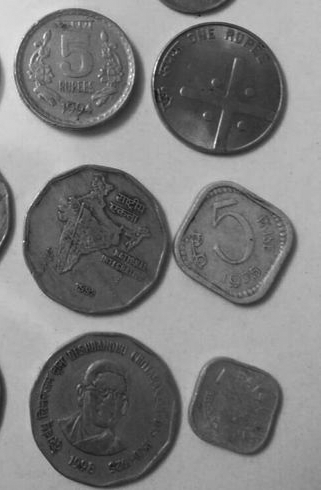

In [2]:
coins = cv2.imread('Monety_szare.bmp', cv2.IMREAD_GRAYSCALE)
Image.fromarray(coins)

Rozwiązanie:

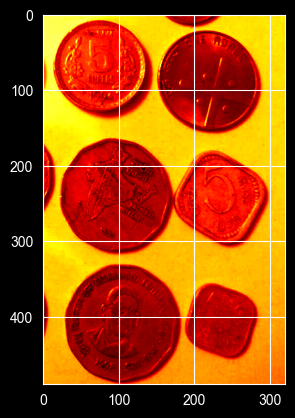

In [3]:
plt.imshow(coins, cmap='hot') # przykład wyświetlania z mapą kolorów

Obraz monet w skali szarości został wyświetlony z użyciem mapy ciepła (hot). Najjaśniejsze obszary tła są odwzorowane w odcieniach żółci i bieli, natomiast ciemniejsze monety przyjmują barwy czerwone i czarne.

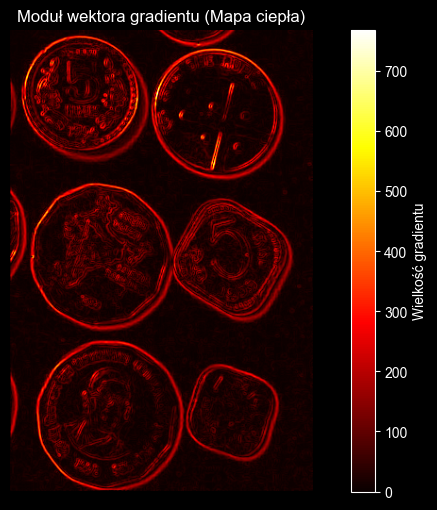

In [4]:
sobelx = cv2.Sobel(coins, cv2.CV_64F, 1, 0, ksize=3)
sobely = cv2.Sobel(coins, cv2.CV_64F, 0, 1, ksize=3)

gradient_magnitude = cv2.magnitude(sobelx, sobely)

plt.figure(figsize=(10, 6))
plt.imshow(gradient_magnitude, cmap='hot')
plt.colorbar(label='Wielkość gradientu')
plt.title('Moduł wektora gradientu (Mapa ciepła)')
plt.axis('off')
plt.show()

* Czarny i ciemnoczerwony kolor (wartości bliskie 0) odpowiadają obszarom jednorodnym, natomiast odcienie jasnoczerwone, pomarańczowe i żółte wskazują miejsca o silnych zmianach jasności (krawędzie).
* Pasek skali (colorbar) wskazuje, że wartość modułu gradientu sięga ponad 700 jednostek na najbardziej wyrazistych krawędziach.


1. **Gdzie gradienty są bliskie zera?**
* Gradienty dążą do zera (obszary czarne na obrazie) w **jednolitym tłu** wokół monet oraz w **płaskich, wygładzonych fragmentach powierzchni monet**, gdzie jasność pikseli nie ulega gwałtownym zmianom.

2. **Czy uzyskany wynik pozwoliłby np. na detekcję poszczególnych obiektów?**
* **Nie bezpośrednio**, chociaż stanowi doskonały punkt wyjścia.
* Moduł gradientu uwypukla krawędzie zewnętrzne monet, ale reaguje również na **wewnętrzne reliefy, cyfry i wzory** znajdujące się na ich powierzchni.


Aby wyodrębnić i zliczyć konkretne obiekty, sam obraz gradientowy wymaga dalszego przetwarzania, np.:
1. **Progowania (binaryzacji)** – w celu odrzucenia słabszych odpowiedzi i uzyskania masek krawędzi.

2. **Operacji morfologicznych** – do domknięcia konturów i wypełnienia wnętrza monet.
3. **Algorytmów detekcji obiektów** – takich jak `cv2.findContours()` lub **Transformacja Hougha dla okręgów** (`cv2.HoughCircles()`).

---

##### Zad. 2: Detekcja krawędzi

Przeprowadź z obrazem `coins_noise` takie przekształcenia, aby zmaksymalizować możliwość rozpoznania obiektów. Wykorzystaj [filtr Canny'ego](https://docs.opencv.org/4.x/dd/d1a/group__imgproc__feature.html#ga04723e007ed888ddf11d9ba04e2232de) do detekcji krawędzi; zbadaj jego zachowanie w zależności od wartości **progów** oraz sposobu redukcji **szumu**.

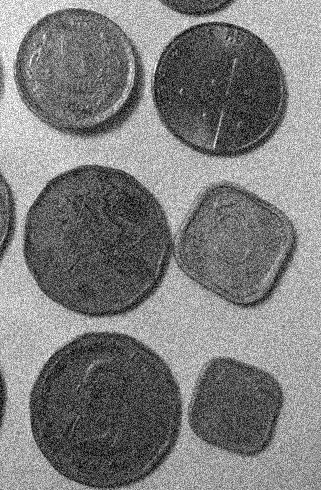

In [5]:
coins_noise = cv2.imread('Monety_szare_szum.bmp', cv2.IMREAD_GRAYSCALE)
Image.fromarray(coins_noise)

Rozwiązanie:

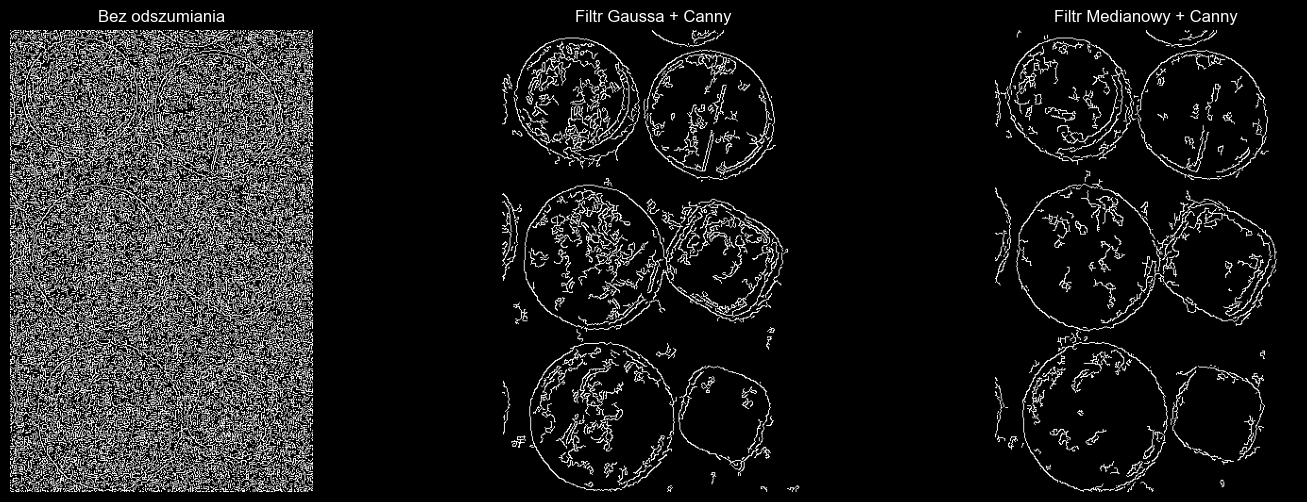

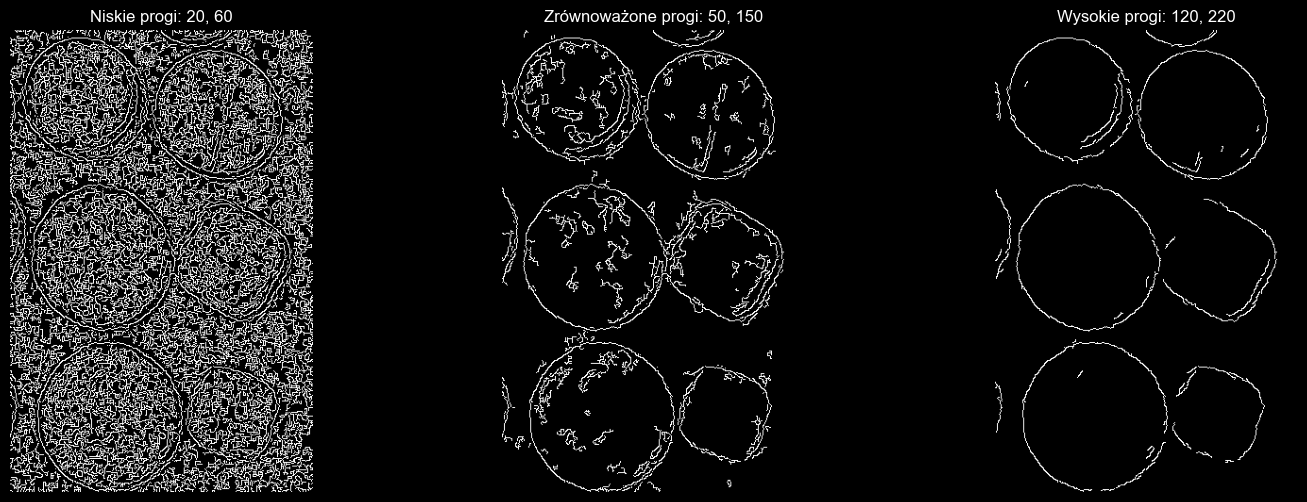

In [6]:
blur_gauss = cv2.GaussianBlur(coins_noise, (5, 5), 0)
blur_median = cv2.medianBlur(coins_noise, 5)

canny_raw = cv2.Canny(coins_noise, 50, 150)
canny_gauss = cv2.Canny(blur_gauss, 50, 150)
canny_median = cv2.Canny(blur_median, 50, 150)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(canny_raw, cmap='gray')
axes[0].set_title('Bez odszumiania')
axes[0].axis('off')

axes[1].imshow(canny_gauss, cmap='gray')
axes[1].set_title('Filtr Gaussa + Canny')
axes[1].axis('off')

axes[2].imshow(canny_median, cmap='gray')
axes[2].set_title('Filtr Medianowy + Canny')
axes[2].axis('off')
plt.show()


canny_low = cv2.Canny(blur_median, 20, 60)
canny_mid = cv2.Canny(blur_median, 50, 150)
canny_high = cv2.Canny(blur_median, 120, 220)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(canny_low, cmap='gray')
axes[0].set_title('Niskie progi: 20, 60')
axes[0].axis('off')

axes[1].imshow(canny_mid, cmap='gray')
axes[1].set_title('Zrównoważone progi: 50, 150')
axes[1].axis('off')

axes[2].imshow(canny_high, cmap='gray')
axes[2].set_title('Wysokie progi: 120, 220')
axes[2].axis('off')
plt.show()

#### Wpływ redukcji szumu
* Obraz wejściowy bez wstępnej filtracji generuje siatkę fałszywych krawędzi na całym tłu, całkowicie uniemożliwiając rozpoznanie obiektów.

* Filtracja Gaussowska liniowo rozmywa obraz, co przy szumie impulsowym nie usuwa zakłóceń całkowicie i pozostawia drobne artefakty.


* Filtracja medianowa eliminuje szum impulsowy bez rozmywania krawędzi, dzięki czemu zapewnia najczystsze tło pod dalszą analizę.

#### Wpływ progów histerezy (dolny rząd)
* **Progi histerezy (20, 60) -** Detektor staje się nadmiernie czuły, wykrywając drobną strukturę powierzchni monet, ich wewnętrzne reliefy oraz resztki zakłóceń.


* **Progi histerezy (120, 220) -** Algorytm odrzuca słabsze reakcje gradientu, co prowadzi do powstawania przerw i utraty ciągłości obrysów monet.


* **Progi histerezy (50, 150) -** Odpowiednio dobrana proporcja progów wycina szum z wnętrza obiektów, zachowując przy tym ich pełne krawędzie zewnętrzne.


* Połączenie filtracji medianowej z właściwymi progami daje czyste, zamknięte kontury, które stanowią bezpośrednie wejście do zliczania i segmentacji monet.

---

##### Zad. 3: Wyrównanie histogramu

Wyrównaj histogram obrazu `coins_noise`. Wyniki zaprezentuj za pomocą obrazów i towarzyszących im histogramów. Powtórz eksperyment z detekcją krawędzi (zad. 2) dla wyrównanego obrazu i omów różnice.

C:\Users\pauko\AppData\Local\Temp\ipykernel_15852\2002138867.py:9: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  axes[0, 1].hist(coins_noise.ravel(), 256, [0, 256], color='gray')
C:\Users\pauko\AppData\Local\Temp\ipykernel_15852\2002138867.py:16: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  axes[1, 1].hist(coins_eq.ravel(), 256, [0, 256], color='gray')


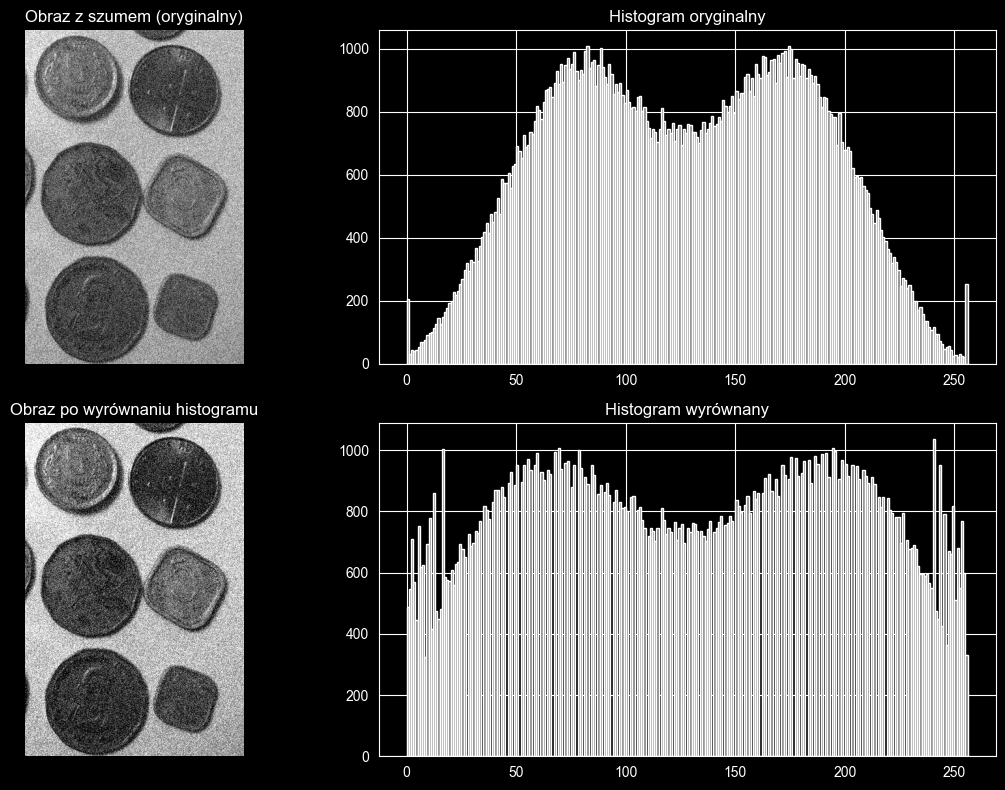

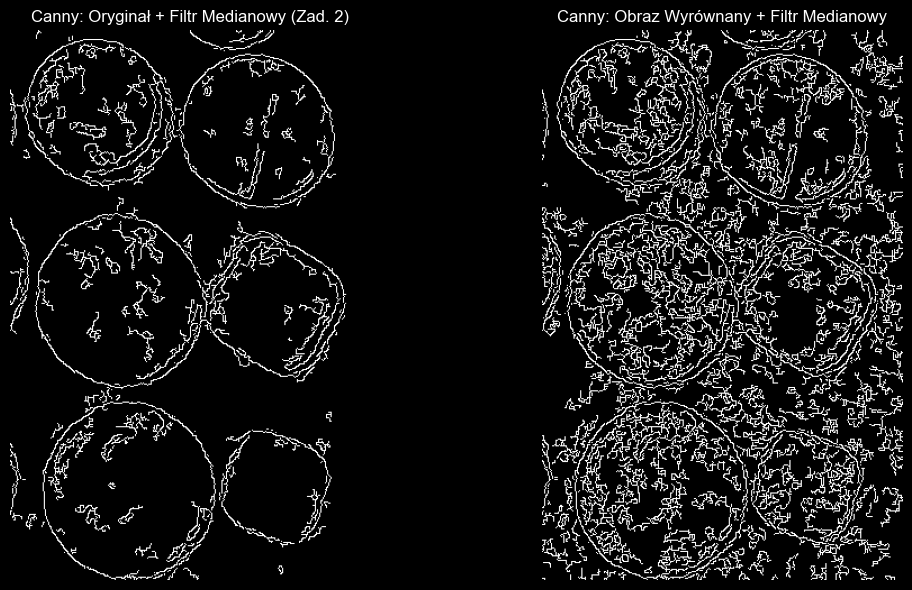

In [9]:
coins_eq = cv2.equalizeHist(coins_noise)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].imshow(coins_noise, cmap='gray')
axes[0, 0].set_title('Obraz z szumem (oryginalny)')
axes[0, 0].axis('off')

axes[0, 1].hist(coins_noise.ravel(), 256, [0, 256], color='gray')
axes[0, 1].set_title('Histogram oryginalny')

axes[1, 0].imshow(coins_eq, cmap='gray')
axes[1, 0].set_title('Obraz po wyrównaniu histogramu')
axes[1, 0].axis('off')

axes[1, 1].hist(coins_eq.ravel(), 256, [0, 256], color='gray')
axes[1, 1].set_title('Histogram wyrównany')

plt.tight_layout()
plt.show()

blur_eq_median = cv2.medianBlur(coins_eq, 5)

canny_orig_median = cv2.Canny(cv2.medianBlur(coins_noise, 5), 50, 150)
canny_eq_median = cv2.Canny(blur_eq_median, 50, 150)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(canny_orig_median, cmap='gray')
axes[0].set_title('Canny: Oryginał + Filtr Medianowy (Zad. 2)')
axes[0].axis('off')

axes[1].imshow(canny_eq_median, cmap='gray')
axes[1].set_title('Canny: Obraz Wyrównany + Filtr Medianowy')
axes[1].axis('off')

plt.tight_layout()
plt.show()

#### Omówienie wyników

* **Oryginał i jego histogram -** Oryginalny obraz zawiera szum impulsowy, a jego histogram jest skupiony w ograniczonej części zakresu tonalnego.


* **Obraz wyrównany i jego histogram -** Wyrównanie histogramu rozciągnęło jasność na całą skalę $[0, 255]$. Efektem ubocznym jest drastyczne podbicie kontrastu szumu w tle oraz uwypuklenie drobnych rys i tłoczeń na monetach.


* **Detekcja Canny na oryginale (lewy dół) -** Połączenie filtra medianowego i algorytmu Canny pozwala uzyskać gładkie tło oraz czyste, spójne obrysy monet.


* **Detekcja Canny na obrazie wyrównanym (prawy dół) -** Detektor Canny generuje gęstą siatkę fałszywych krawędzi zarówno na tłu, jak i wewnątrz obiektów.

#### Główne różnice

1. Wyrównanie histogramu drastycznie zwiększa różnice tonalne pomiędzy pikselami szumu a tłem. Przez to filtr medianowy nie jest w stanie całkowicie wygładzić zakłóceń przed detekcją krawędzi.


2. Wzmocniony szum tworzy sztuczne, silne gradienty, które przekraczają progi histerezy i są błędnie kwalifikowane jako krawędzie obiektów.


3. Obraz wynikowy dla oryginału nadaje się do natychmiastowej segmentacji i zliczania monet, natomiast wynik dla obrazu wyrównanego jest nieczytelny i zaszumiony.


Nie należy wykonywać globalnego wyrównywania histogramu przed detekcją krawędzi na obrazach zaszumionych. Operacja ta zwiększa poziom zakłóceń i uniemożliwia poprawną detekcję obrysów obiektów.

---

##### Zad. 4: Transformacja do rozkładu docelowego

Dla obrazów `albatross_single` (od tego zacznij) i `albatross_crowd` wykonaj transformację do wybranego (założonego przez siebie) rozkładu docelowego, tak aby zmaksymalizować możliwość wyodrębnienia obiektów (albatrosów) z otoczenia przy użyciu algorytmu binaryzacji Otsu. Zbadaj wpływ kształtu rozkładu docelowego na zachowanie transformacji.  
Jaki(e) parametr(y) rozkładu są najistotniejsze?

Podpowiedź: przedstawiona we wstępie teoretycznym transformacja obu rozkładów (źródłowego i docelowego) do rozkładu jednostajnego nie musi zostać wykonana _wprost_ (dlatego nie używaj w zadaniu funkcji `cv2.equalizeHist`)! Wystarczy porównywanie ze sobą wartości ze skumulowanych rozkładów (rysunek 3).

Podpowiedź 2: [`cv2.LUT`](https://docs.opencv.org/4.5.3/d2/de8/group__core__array.html#gab55b8d062b7f5587720ede032d34156f)

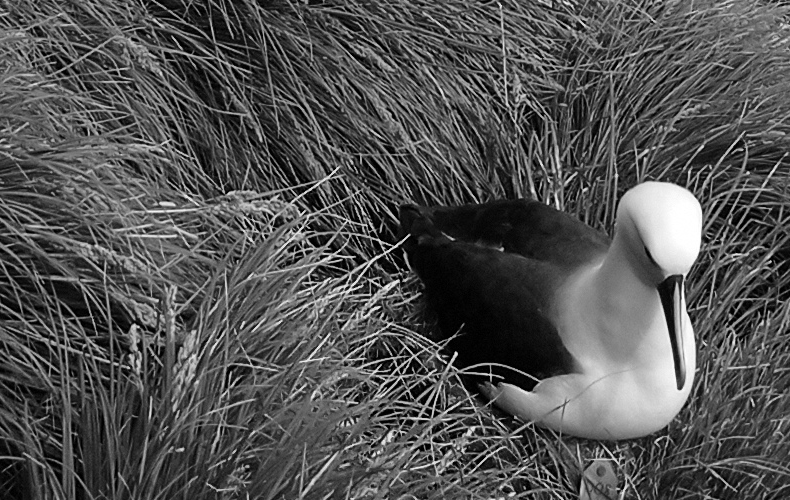

In [7]:
albatross_single = cv2.imread('albatross_single.png', cv2.IMREAD_GRAYSCALE)
Image.fromarray(albatross_single)

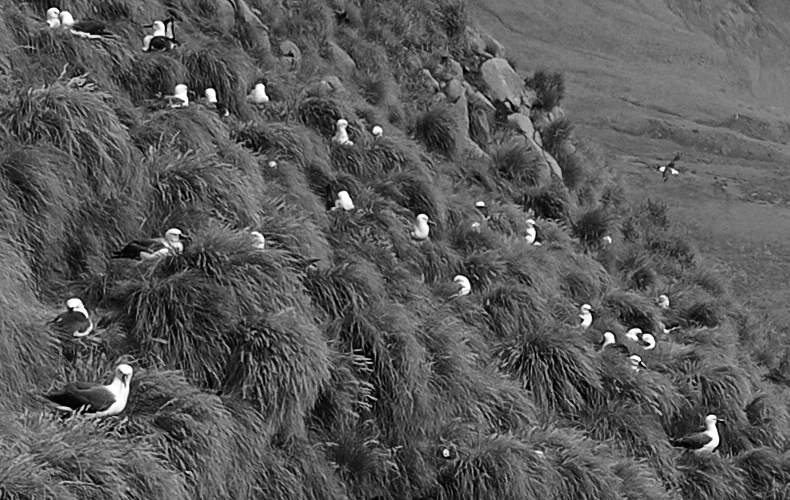

In [8]:
albatross_crowd = cv2.imread('albatross_crowd.png', cv2.IMREAD_GRAYSCALE)
Image.fromarray(albatross_crowd)

Rozwiązanie:

C:\Users\pauko\AppData\Local\Temp\ipykernel_15852\1797072956.py:39: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  axes[0, 1].hist(img.ravel(), 256, [0, 256], color='gray')
C:\Users\pauko\AppData\Local\Temp\ipykernel_15852\1797072956.py:50: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  axes[1, 1].hist(img_matched.ravel(), 256, [0, 256], color='blue', alpha=0.6)


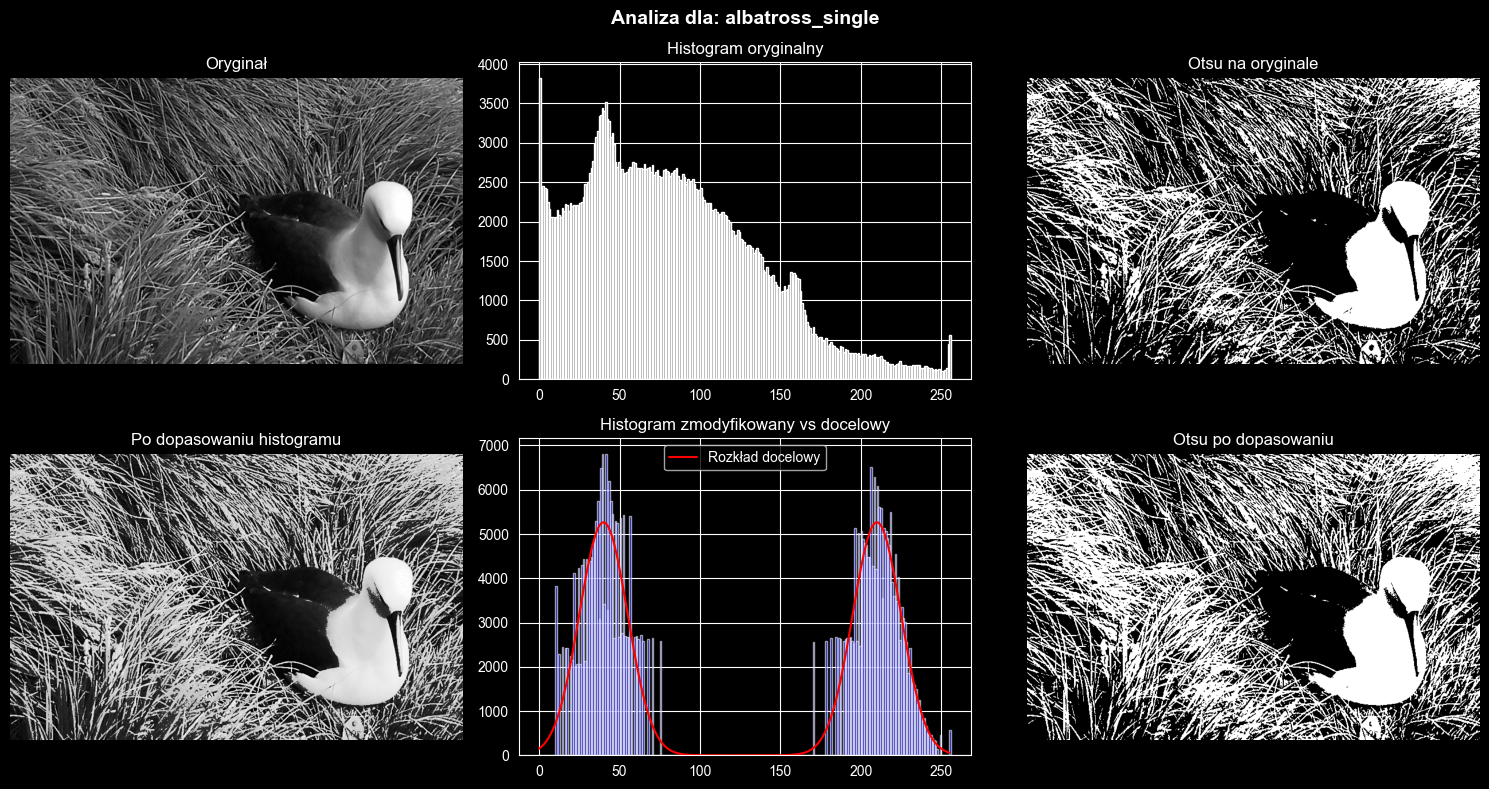

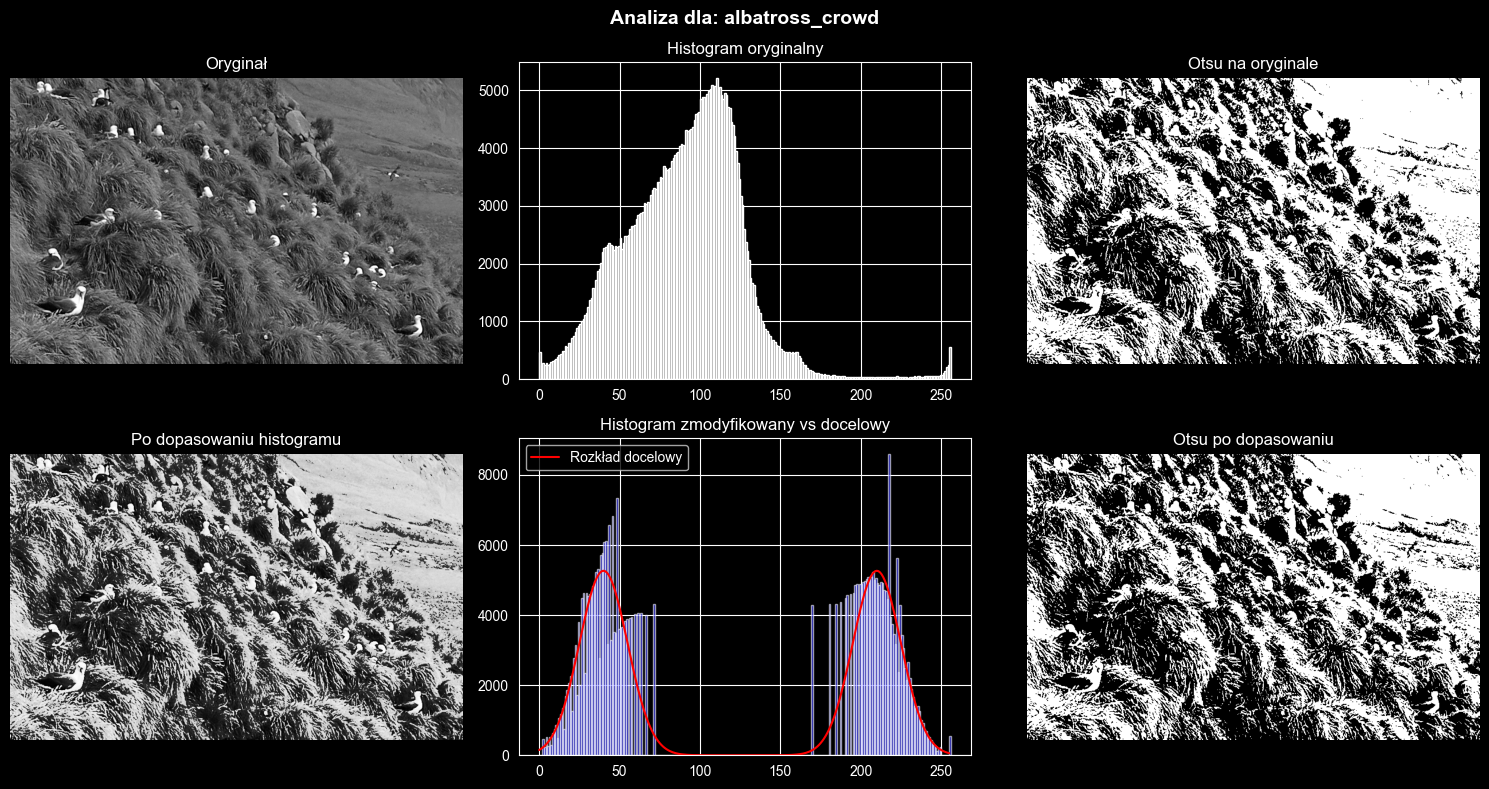

In [10]:
def histogram_matching(img, target_pdf):
    hist_src, _ = np.histogram(img.flatten(), 256, [0, 256])
    pdf_src = hist_src / hist_src.sum()
    cdf_src = pdf_src.cumsum()

    pdf_target = target_pdf / target_pdf.sum()
    cdf_target = pdf_target.cumsum()

    lut = np.zeros(256, dtype=np.uint8)
    for src_val in range(256):
        idx = np.argmin(np.abs(cdf_target - cdf_src[src_val]))
        lut[src_val] = idx

    img_matched = cv2.LUT(img, lut)
    return img_matched

x = np.arange(256)
mu1, sigma1, weight1 = 40, 15, 0.5   # Ciemne tło / obiekt
mu2, sigma2, weight2 = 210, 15, 0.5  # Jasny obiekt / tło

bimodal_pdf = (weight1 * np.exp(-0.5 * ((x - mu1) / sigma1)**2) +
               weight2 * np.exp(-0.5 * ((x - mu2) / sigma2)**2))

images = {'albatross_single': albatross_single, 'albatross_crowd': albatross_crowd}

for name, img in images.items():
    img_matched = histogram_matching(img, bimodal_pdf)

    _, otsu_orig = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    _, otsu_matched = cv2.threshold(img_matched, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    fig.suptitle(f'Analiza dla: {name}', fontsize=14, fontweight='bold')

    axes[0, 0].imshow(img, cmap='gray')
    axes[0, 0].set_title('Oryginał')
    axes[0, 0].axis('off')

    axes[0, 1].hist(img.ravel(), 256, [0, 256], color='gray')
    axes[0, 1].set_title('Histogram oryginalny')

    axes[0, 2].imshow(otsu_orig, cmap='gray')
    axes[0, 2].set_title('Otsu na oryginale')
    axes[0, 2].axis('off')

    axes[1, 0].imshow(img_matched, cmap='gray')
    axes[1, 0].set_title('Po dopasowaniu histogramu')
    axes[1, 0].axis('off')

    axes[1, 1].hist(img_matched.ravel(), 256, [0, 256], color='blue', alpha=0.6)
    axes[1, 1].plot(x, bimodal_pdf * (img.size / bimodal_pdf.sum()), color='red', label='Rozkład docelowy')
    axes[1, 1].set_title('Histogram zmodyfikowany vs docelowy')
    axes[1, 1].legend()

    axes[1, 2].imshow(otsu_matched, cmap='gray')
    axes[1, 2].set_title('Otsu po dopasowaniu')
    axes[1, 2].axis('off')

    plt.tight_layout()
    plt.show()

#### 1. `albatross_single`

* **Przed transformacją:** Histogram oryginalny posiada szeroki, spłaszczony rozkład bez wyraźnie oddzielonych szczytów. Binaryzacja Otsu na oryginale radzi sobie poprawnie z główną sylwetką albatrosa, ale tło z trawy jest miejscami poszarpane i zaszumione.


* **Po transformacji:** Histogram przyjmuje czysty, bimodalny kształt z wyraźną doliną przy wartości szarości $\approx 125$.


* **Efekt Otsu:** Krawędzie białego upierzenia albatrosa oraz kontur głowy stają się bardziej spójne, a jasne elementy tła są lepiej zrównoważone.



#### 2. `albatross_crowd`

* **Przed transformacją:** Histogram oryginalny jest mocno **jednomodalny** (skupiony wokół wartości 100–110), ponieważ cały obraz zdominowany jest przez średnie odcienie szarości skał i trawy. Otsu na oryginale gubi szczegóły i ma trudności z poprawną segmentacją małych obiektów.


* **Po transformacji:** Jednowierzchołkowy rozkład zostaje sztucznie rozdzielony na dwa skupiska (ciemne tło oraz jasne obiekty).


* **Efekt Otsu:** Sylwetki poszczególnych albatrosów w stadzie stają się znacznie wyraźniejszymi, jaśniejszymi punktami na tle otoczenia, co ułatwia ich późniejsze zliczanie lub detekcję.


#### Wnioski

* Przekształcenie do rozkładu bimodalnego działa jako **sztuczne wzmocnienie kontrastu klasowego**.


* Operacja ta jest szczególnie pomocna dla obrazów trudnych, o jednolicie szarym lub niemodalnym histogramie (jak `albatross_crowd`), gdzie klasyczny algorytm Otsu bez wstępnego przetwarzania zawodzi.